# Dataset em Análise

Para esta análise foram unidos três dos datasets originais: PV_01.csv, PV_02.csv e PV_rooftop_1337_specannualyield.csv. Isto porque retratam para o mesmo tempo (1-1-2019 a 31-12-2019) a produção elétrica do Campus Universitário

In [6]:
import pandas as pd

base = "../../dataset/UVTgv_OD/production/"

pv_geral = pd.read_csv(base + "PV_geral_com_data.csv", sep=';')



# 4.1 Análise exploratória dos dados 

## Total de Registos

Chegamos a um resultados de 8760 registos o que equivale aos 365 dias do ano * 24 horas. Por esse motivo para melhor análise foi acrescentado uma coluna Datetime, onde relata o dia e a hora indicada de cada linha, para podermos analisar mês e horário de produção

In [7]:
total_registos = len(pv_geral)
print(f"Total de registos pv_geral: {total_registos}")

total_linhas = pv_geral.shape[0]
print(f"Total de linhas (shape) pv_geral: {total_linhas}")



Total de registos pv_geral: 8760
Total de linhas (shape) pv_geral: 8760


## Variável de consumo a prever e respetivas unidades

In [8]:
# Criar a estrutura com os metadados das colunas do seu dataset
metadados = {
    "coluna": ["Datetime", "pv_01", "pv_02", "pv_roof"],
    "dtype": [
        str(pv_geral["Datetime"].dtype), 
        str(pv_geral["pv_01"].dtype), 
        str(pv_geral["pv_02"].dtype), 
        str(pv_geral["pv_roof"].dtype)
    ],
    "unidade": ["hora", "kWh/kWp", "kWh/kWp", "kWh/kWp"],
    "escala": ["intervalo", "razao", "razao", "razao"],
    "nota": [
        "Coluna de data e hora hora a hora (resolução de 1 hora). Usada como eixo temporal.",
        "Produção fotovoltaica do parque n1",
        "Produção fotovoltaica do parque n2",
        "Produção fotovoltaica do parque n3 (telhado do edifício)"
    ]
}

# Converter num DataFrame do Pandas e definir a coluna 'coluna' como índice
df_metadados = pd.DataFrame(metadados)
df_metadados.set_index("coluna", inplace=True)

# Remover o nome do índice para ficar visualmente igual ao exemplo
df_metadados.index.name = None

# Exibir a tabela completa
print(df_metadados.to_string())

            dtype  unidade     escala                                                                                nota
Datetime      str     hora  intervalo  Coluna de data e hora hora a hora (resolução de 1 hora). Usada como eixo temporal.
pv_01     float64  kWh/kWp      razao                                                  Produção fotovoltaica do parque n1
pv_02     float64  kWh/kWp      razao                                                  Produção fotovoltaica do parque n2
pv_roof   float64  kWh/kWp      razao                            Produção fotovoltaica do parque n3 (telhado do edifício)


C:\Users\adria\AppData\Local\Temp\ipykernel_16612\666965758.py:22: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_metadados.set_index("coluna", inplace=True)


## Distribuição e variabilidade do consumo
Após a análise de distribuição podemos concluir que temos uma distribuição idêntica nos três parques, sendo esta assimétrica positiva

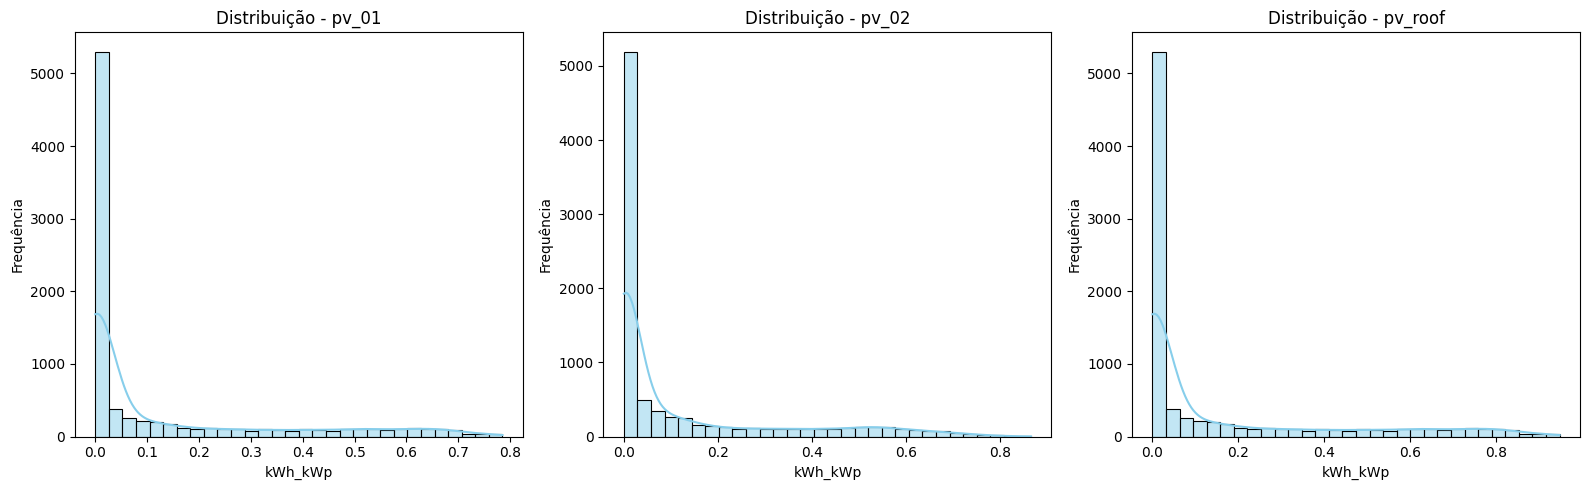

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garantir que a coluna Datetime está em formato de data/hora
pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])

colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# --- 2. GRÁFICOS DE DISTRIBUIÇÃO (Histogramas / KDE) ---
plt.figure(figsize=(16, 5))

for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    # Filtramos valores > 0 opcionalmente para focar na produção efetiva, 
    # mas aqui usamos todos os dados para ver o retrato completo
    sns.histplot(pv_geral[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribuição - {col}')
    plt.xlabel('kWh_kWp')
    plt.ylabel('Frequência')

plt.tight_layout()
plt.savefig("distribuicoes_histogramas.png", dpi=150)
plt.show()


## Valores em Falta ou Inconsistentes
Na análise de valores em falta podemos observar que não existe nenhum valor em falta.
Como valores inconsistentes foram analisados os seguintes fatores:
- valores negativos
- produção à noite(onde temos em consideração as estações do ano)
- ter valores de produção acima de 1,0
- ter valores nulos ao meio dia no verão 
- ter um valor maior que 0 constante por mais de 6 horas

Após esta análise chegamos a 89 casos de produção de energia à noite. Por esse motivo, foi necessário proceder à análise destes para perceber o porquê destes valores, se seriam valores errados ou simplesmente valores fora do comum. Em primeiro lugar identificámos as horas e os meses em que estes foram identificados (sendo idenificados entre abril e agosto todos as 5 da manhã, havendo mais valores nos meses intermédios) e também os valores de energia.

In [10]:
# --- 1. Contar valores em falta por coluna (Global) ---
print("--- Número de valores em falta por coluna ---")
print(pv_geral.isnull().sum())

--- Número de valores em falta por coluna ---
pv_01       0
pv_02       0
pv_roof     0
Datetime    0
dtype: int64


In [11]:
pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])
pv_geral = pv_geral.sort_values("Datetime").reset_index(drop=True)

problemas = []

def registar(mask, serie, motivo):
    sub = pv_geral.loc[mask, ["Datetime", serie]].copy()
    sub["serie"] = serie
    sub["motivo"] = motivo
    sub = sub.rename(columns={serie: "valor"})
    problemas.append(sub)

hora = pv_geral["Datetime"].dt.hour
noite = hora.isin([21, 22, 23, 0, 1, 2, 3, 4, 5])      # janela segura de noite
meio_dia = hora.isin([10, 11, 12, 13, 14])
mes_sol = pv_geral["Datetime"].dt.month.isin([5, 6, 7, 8, 9])

SERIES = ["pv_01", "pv_02", "pv_roof"]

for s in SERIES:
    v = pv_geral[s]
    registar(v < 0, s, "negativo")
    registar(noite & (v > 0.01), s, "produção à noite")
    registar(v > 1.0, s, "acima de 1,0")
    # zeros ao meio-dia em meses de sol (suspeito, não certo)
    registar(meio_dia & mes_sol & (v == 0), s, "zero ao meio-dia no verão (suspeito)")

# timestamps
dup = pv_geral["Datetime"].duplicated(keep=False)
registar(dup, SERIES[0], "timestamp duplicado")

# buracos: horas em falta
esperado = pd.date_range(pv_geral["Datetime"].min(), pv_geral["Datetime"].max(), freq="h")
em_falta = esperado.difference(pv_geral["Datetime"])
print("Horas em falta:", len(em_falta))
print(em_falta[:20])

# séries repetidas / constantes
print("pv_01 == pv_roof ?", pv_geral["pv_01"].equals(pv_geral["pv_roof"]))
for s in SERIES:
    corridas = (pv_geral[s] != pv_geral[s].shift()).cumsum()
    tamanho = pv_geral.groupby(corridas)[s].transform("size")
    registar((tamanho >= 6) & (pv_geral[s] > 0), s, "valor constante >0 durante 6+ horas")

res = pd.concat(problemas).sort_values(["serie", "Datetime"])

# Tabela: tipo de erro (linhas) x coluna (colunas)
motivos_todos = [
    "negativo",
    "produção à noite",
    "acima de 1,0",
    "zero ao meio-dia no verão",
    "valor constante >0 durante 6+ horas",
]

tabela = (res.groupby(["motivo", "serie"]).size()
            .unstack(fill_value=0)
            .reindex(index=motivos_todos, columns=SERIES, fill_value=0))

print(tabela.to_string())

res.to_csv("valores_impossiveis.csv", index=False)
print('')
print("\n--- Primeiras 10 linhas do DataFrame de problemas ---")
print(res.head(10))

Horas em falta: 0
DatetimeIndex([], dtype='datetime64[us]', freq='h')
pv_01 == pv_roof ? False
serie                                pv_01  pv_02  pv_roof
motivo                                                    
negativo                                 0      0        0
produção à noite                         0     89        0
acima de 1,0                             0      0        0
zero ao meio-dia no verão                0      0        0
valor constante >0 durante 6+ horas      0      0        0


--- Primeiras 10 linhas do DataFrame de problemas ---
                Datetime     valor  serie            motivo
2621 2019-04-20 05:00:00  0.010407  pv_02  produção à noite
2645 2019-04-21 05:00:00  0.011057  pv_02  produção à noite
2669 2019-04-22 05:00:00  0.015285  pv_02  produção à noite
2693 2019-04-23 05:00:00  0.012033  pv_02  produção à noite
2741 2019-04-25 05:00:00  0.014959  pv_02  produção à noite
2765 2019-04-26 05:00:00  0.016911  pv_02  produção à noite
2789 2019-04-27 

C:\Users\adria\AppData\Local\Temp\ipykernel_16612\2922681724.py:9: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  res["dia_ano"] = res["Datetime"].dt.dayofyear


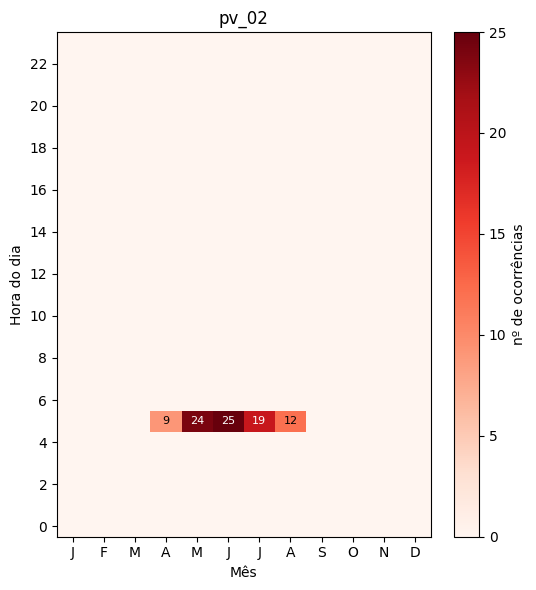

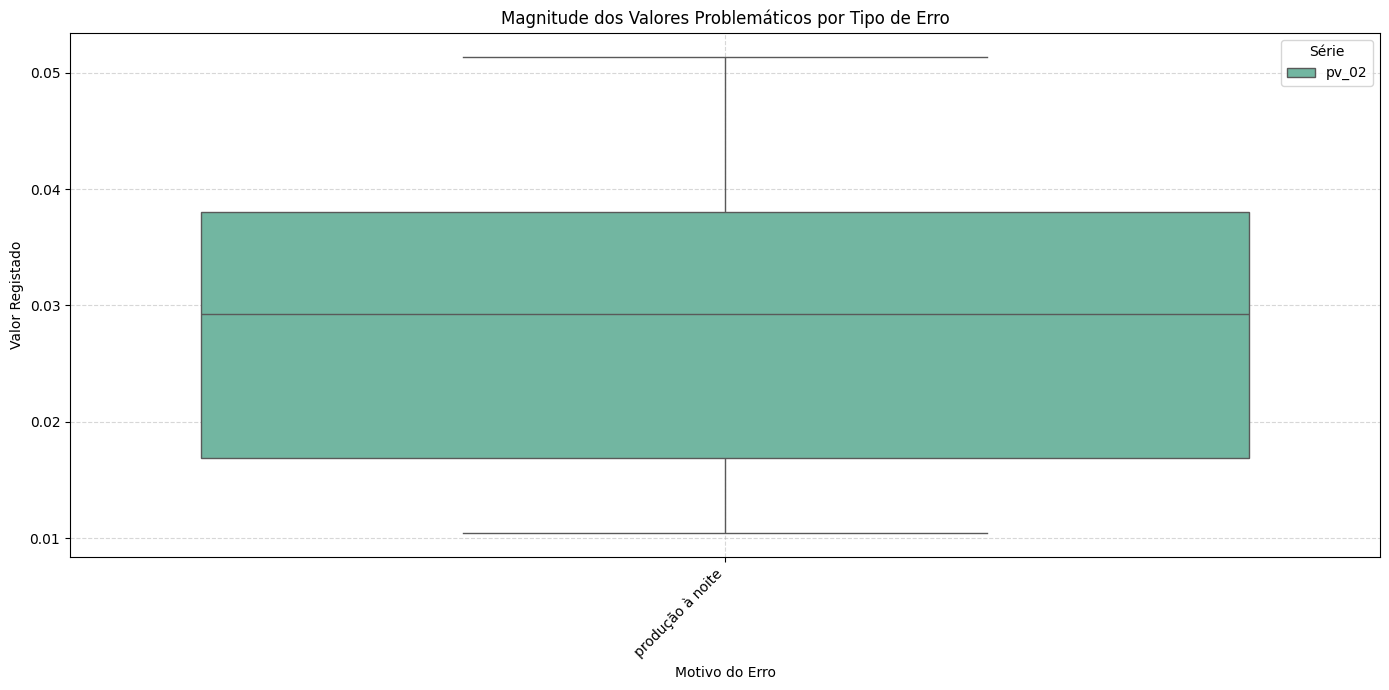

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

res = pd.read_csv("valores_impossiveis.csv", parse_dates=["Datetime"])
res["hora"] = res["Datetime"].dt.hour
res["mes"] = res["Datetime"].dt.month
res["dia_ano"] = res["Datetime"].dt.dayofyear

# Verão = abril a setembro; Inverno = outubro a março
res["estacao"] = np.where(res["mes"].between(4, 9), "Verão (abr–set)", "Inverno (out–mar)")

series = sorted(res["serie"].unique())
motivos = sorted(res["motivo"].unique())
cores = dict(zip(motivos, plt.cm.tab10.colors))

# ---------- 2) Mapa de calor: hora (y) vs mês (x), contagem com valores impressos ----------
fig, axs = plt.subplots(1, len(series), figsize=(5.5 * len(series), 6),
                        sharey=True, squeeze=False)

for ax, s in zip(axs[0], series):
    m = (res[res["serie"] == s]
         .pivot_table(index="hora", columns="mes", values="valor", aggfunc="size", fill_value=0)
         .reindex(index=range(24), columns=range(1, 13), fill_value=0))
    
    im = ax.imshow(m.values, aspect="auto", origin="lower", cmap="Reds")
    
    # --- NOVO: Adicionar os valores numéricos em cada célula do mapa de calor ---
    matriz_valores = m.values
    max_val = matriz_valores.max() if matriz_valores.max() > 0 else 1
    
    for i in range(matriz_valores.shape[0]):      # Linhas (horas)
        for j in range(matriz_valores.shape[1]):  # Colunas (meses)
            val = matriz_valores[i, j]
            if val > 0:  # Opcional: mostrar apenas se for maior que 0 para não poluir
                # Se o fundo for muito escuro, o texto passa a branco
                cor_texto = "white" if val > (max_val * 0.6) else "black"
                ax.text(j, i, str(val), ha="center", va="center", color=cor_texto, fontsize=8)
    # --------------------------------------------------------------------------

    ax.set_xticks(range(12))
    ax.set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"])
    ax.set_yticks(range(0, 24, 2))
    ax.set_title(s)
    ax.set_xlabel("Mês")
    fig.colorbar(im, ax=ax, label="nº de ocorrências")

axs[0, 0].set_ylabel("Hora do dia")
fig.tight_layout()
fig.savefig("impossiveis_heatmap.png", dpi=150)

# ---------- 3) Novo Gráfico: Magnitude dos Valores Anómalos por Motivo e Série ----------
plt.figure(figsize=(14, 7))

# Criamos um boxplot para ver a distribuição dos valores problemáticos
sns.boxplot(
    data=res, 
    x="motivo", 
    y="valor", 
    hue="serie", 
    palette="Set2"
)

plt.xticks(rotation=45, ha="right")
plt.title("Magnitude dos Valores Problemáticos por Tipo de Erro")
plt.xlabel("Motivo do Erro")
plt.ylabel("Valor Registado")
plt.legend(title="Série")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("magnitude_erros_boxplot.png", dpi=150)

plt.show()

## Evolução da produção fotovoltaica ao longo do tempo

Após esta análise concluí-se o que já se previa. Existe uma maior produção em meses de mais exposição solar (verão), e que nas horas de pico de solar (entre as 11 horas e as 14 horas)

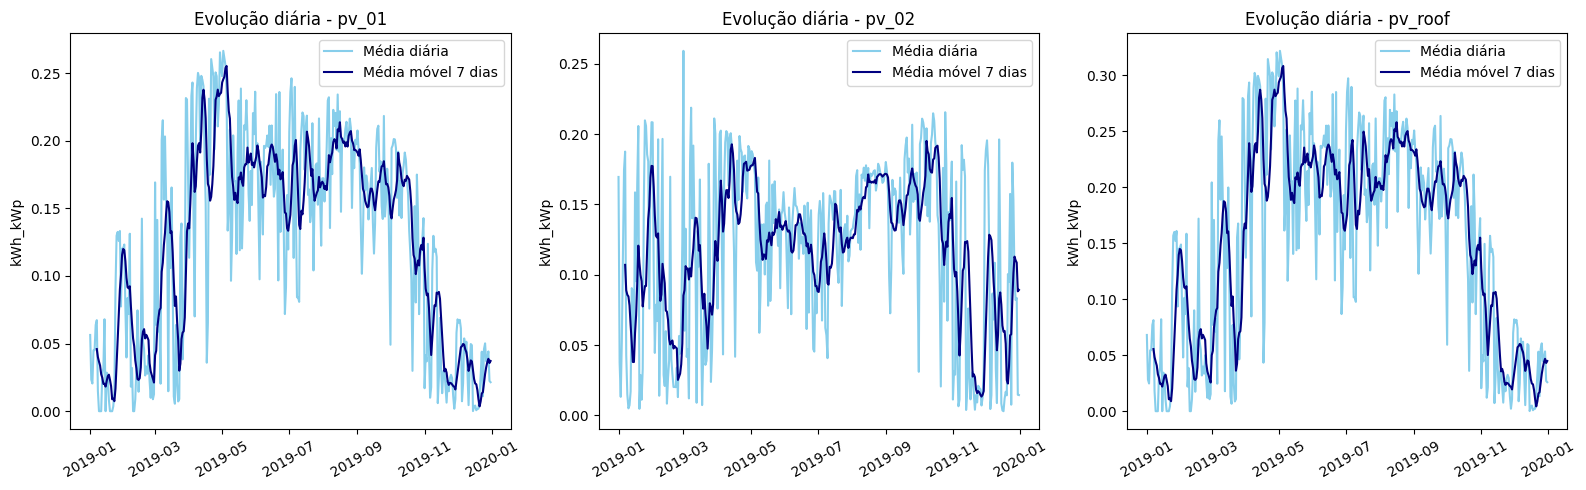

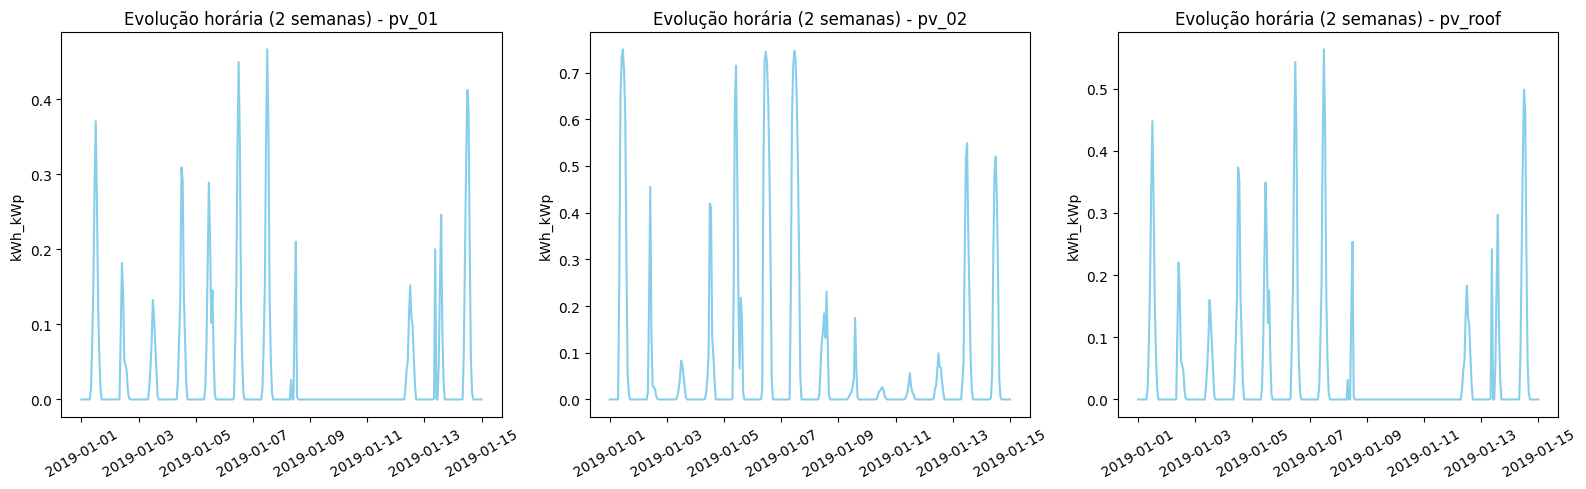

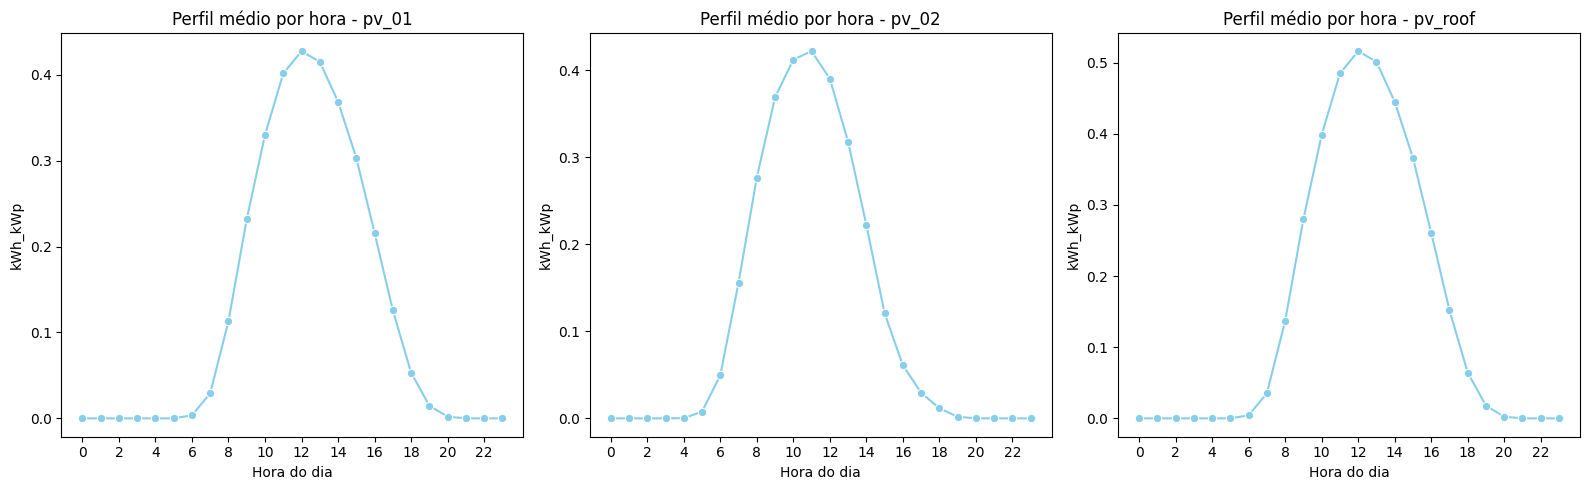

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pv_geral["Datetime"] = pd.to_datetime(pv_geral["Datetime"])
pv_idx = pv_geral.set_index("Datetime").sort_index()

colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# --- 1. EVOLUÇÃO DIÁRIA (média diária + média móvel 7 dias) ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    diario = pv_idx[col].resample("D").mean()
    sns.lineplot(x=diario.index, y=diario.values, label="Média diária", color="skyblue")
    sns.lineplot(x=diario.index, y=diario.rolling(7).mean().values,
                 label="Média móvel 7 dias", color="navy")
    plt.title(f"Evolução diária - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("evolucao_diaria.png", dpi=150)
plt.show()

# --- 2. EVOLUÇÃO HORÁRIA (primeiras 2 semanas, para ficar legível) ---
inicio = pv_idx.index.min()
janela = pv_idx.loc[inicio : inicio + pd.Timedelta(days=14)]

plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    sns.lineplot(x=janela.index, y=janela[col].values, color="skyblue")
    plt.title(f"Evolução horária (2 semanas) - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp")
    plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("evolucao_horaria.png", dpi=150)
plt.show()

# --- 3. PERFIL MÉDIO POR HORA DO DIA (0-23h) ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    perfil = pv_idx[col].groupby(pv_idx.index.hour).mean()
    sns.lineplot(x=perfil.index, y=perfil.values, marker="o", color="skyblue")
    plt.title(f"Perfil médio por hora - {col}")
    plt.xlabel("Hora do dia")
    plt.ylabel("kWh_kWp")
    plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("perfil_horario.png", dpi=150)
plt.show()

## Padrões diários, semanais e sazonais, quando identificáveis

Novamente com esta análise verificou-se os padrões sazonais, que as estações mais quentes têm mais produção. A nível semanal podemos notar um padrão entre parques que considero enganoso, pois isso não significa nada em concreto, todos são analisados nos mesmos dias e isso faz com que a média por dia de semana tenha mais ou menos sempre a mesma produção, mas não significa que um dia produz mais que outro. Por meses nota-se novamente 

C:\Users\adria\AppData\Local\Temp\ipykernel_16612\4220925211.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pv_idx["dia_semana"] = pv_idx.index.dayofweek      # 0 = segunda


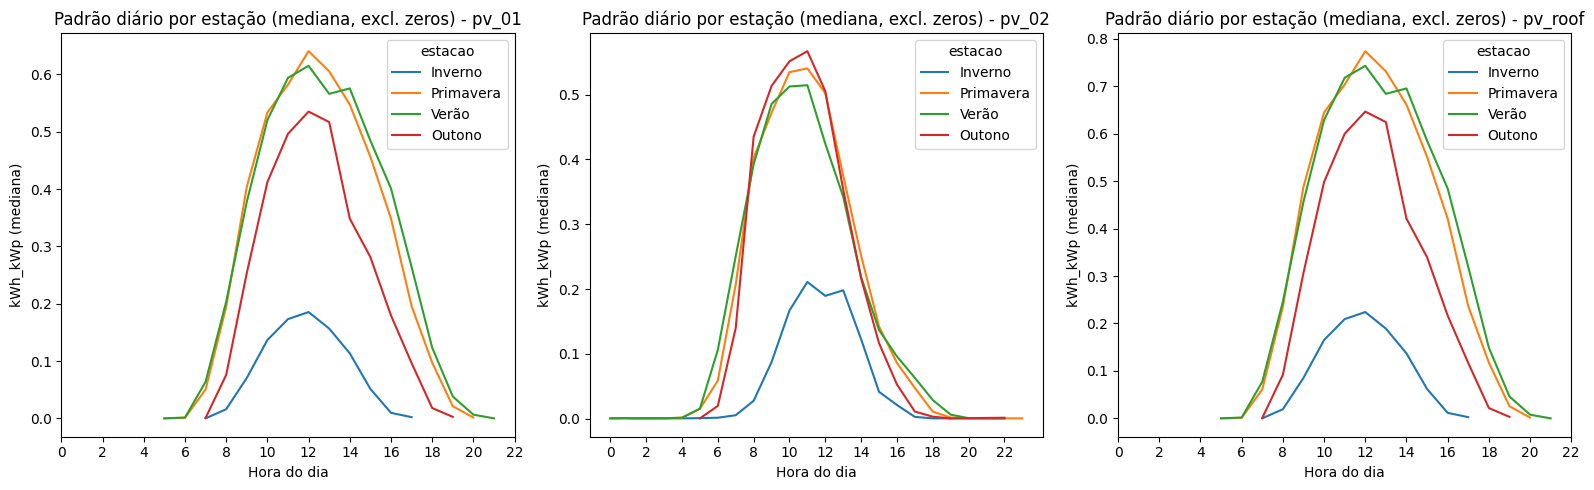

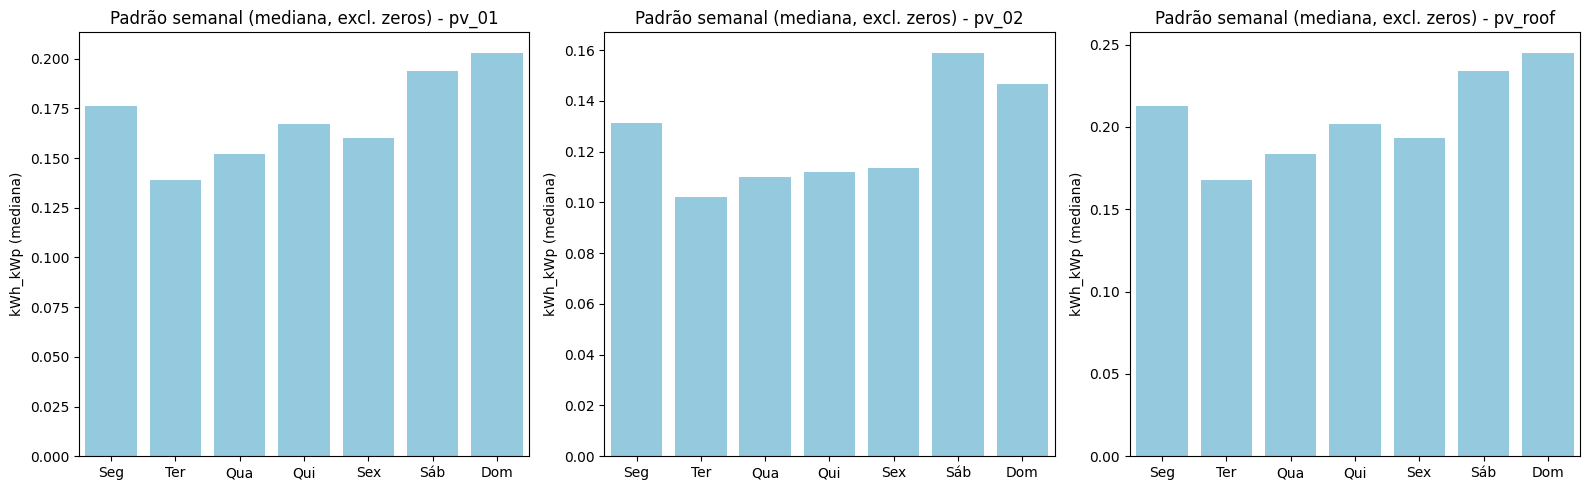

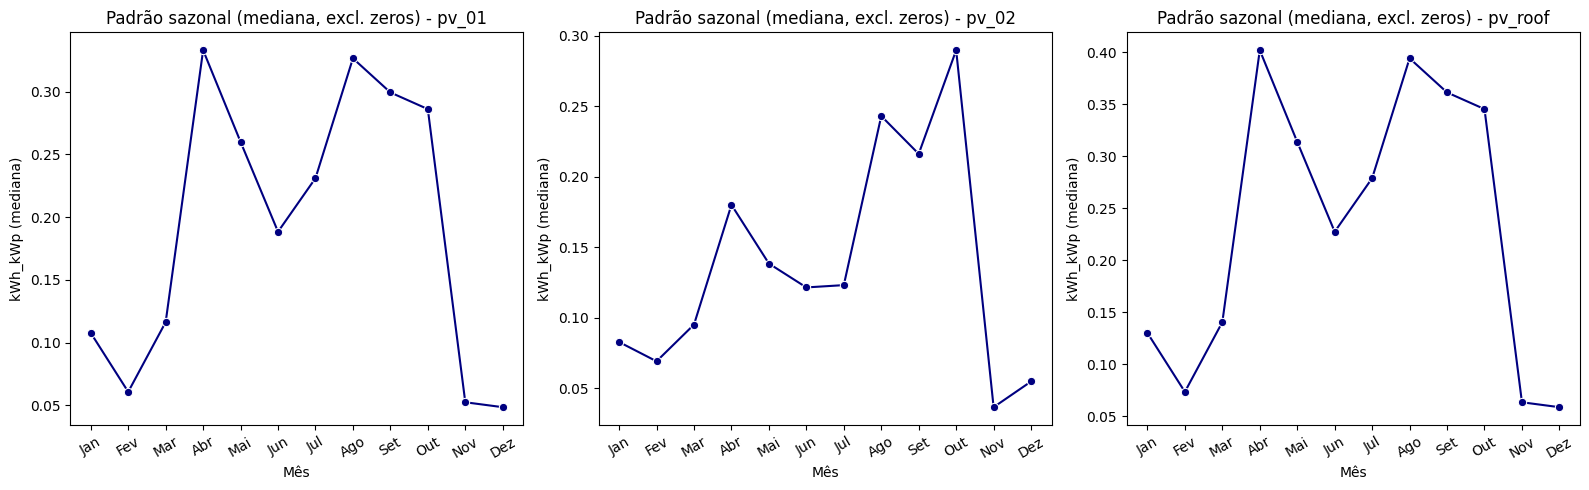

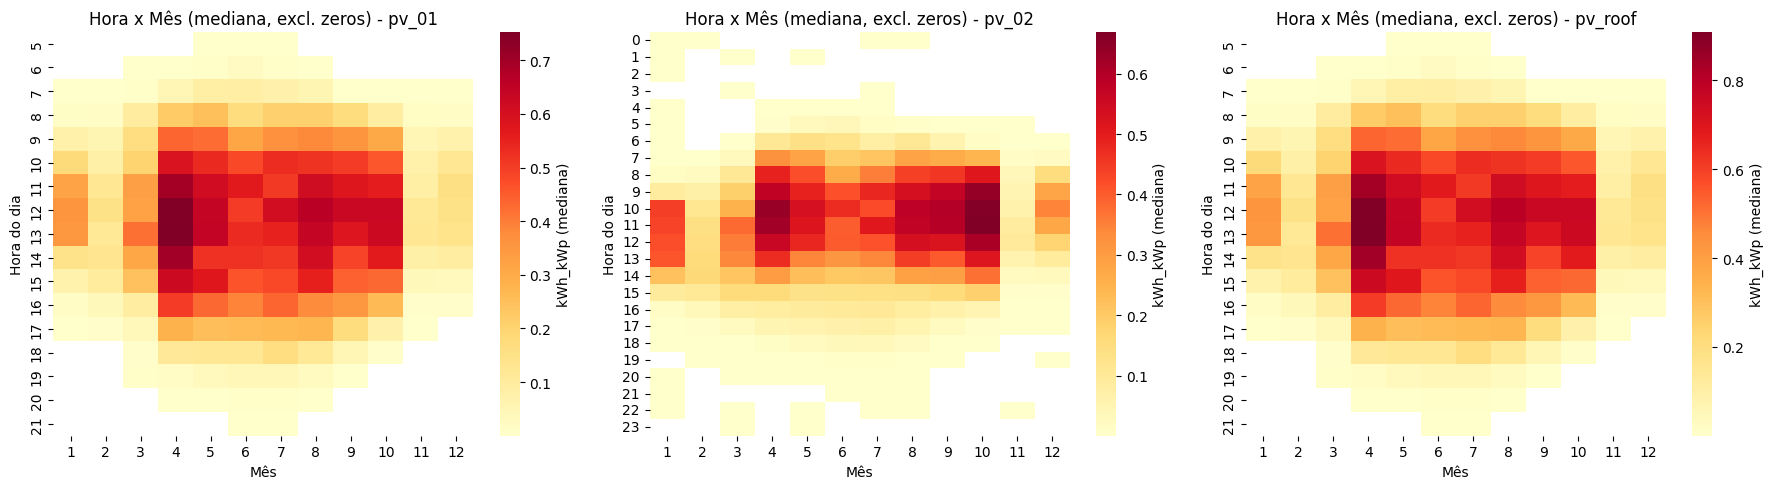

In [14]:


pv_idx = pv_geral.set_index("Datetime").sort_index()
colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# Variáveis temporais auxiliares
pv_idx["hora"] = pv_idx.index.hour
pv_idx["dia_semana"] = pv_idx.index.dayofweek      # 0 = segunda
pv_idx["mes"] = pv_idx.index.month

nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
               "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

def estacao(m):
    return ("Inverno" if m in (12, 1, 2) else
            "Primavera" if m in (3, 4, 5) else
            "Verão" if m in (6, 7, 8) else "Outono")

pv_idx["estacao"] = pv_idx["mes"].map(estacao)

# --- VERSÃO SEM ZEROS (só para análise visual; pv_idx fica intacto) ---
pv_nz = pv_idx.copy()
pv_nz[colunas_producao] = pv_nz[colunas_producao].replace(0, np.nan)

# --- 1. PADRÃO DIÁRIO: mediana por hora, separado por estação ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    perfil = pv_nz.groupby(["estacao", "hora"])[col].median().reset_index()
    sns.lineplot(data=perfil, x="hora", y=col, hue="estacao",
                 hue_order=["Inverno", "Primavera", "Verão", "Outono"])
    plt.title(f"Padrão diário por estação (mediana, excl. zeros) - {col}")
    plt.xlabel("Hora do dia")
    plt.ylabel("kWh_kWp (mediana)")
    plt.xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig("padrao_diario_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 2. PADRÃO SEMANAL: mediana por dia da semana ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    semanal = pv_nz.groupby("dia_semana")[col].median().reindex(range(7))
    sns.barplot(x=nomes_dias, y=semanal.values, color="skyblue")
    plt.title(f"Padrão semanal (mediana, excl. zeros) - {col}")
    plt.xlabel("")
    plt.ylabel("kWh_kWp (mediana)")
plt.tight_layout()
plt.savefig("padrao_semanal_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 3. PADRÃO SAZONAL: mediana por mês ---
plt.figure(figsize=(16, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    mensal = pv_nz.groupby("mes")[col].median().reindex(range(1, 13))
    sns.lineplot(x=mensal.index, y=mensal.values, marker="o", color="navy")
    plt.title(f"Padrão sazonal (mediana, excl. zeros) - {col}")
    plt.xlabel("Mês")
    plt.ylabel("kWh_kWp (mediana)")
    plt.xticks(range(1, 13), nomes_meses, rotation=30)
plt.tight_layout()
plt.savefig("padrao_sazonal_mediana_sem_zeros.png", dpi=150)
plt.show()

# --- 4. MAPA DE CALOR hora x mês (mediana) ---
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    tabela = pv_nz.pivot_table(index="hora", columns="mes", values=col, aggfunc="median")
    sns.heatmap(tabela, cmap="YlOrRd", cbar_kws={"label": "kWh_kWp (mediana)"})
    plt.title(f"Hora x Mês (mediana, excl. zeros) - {col}")
    plt.xlabel("Mês")
    plt.ylabel("Hora do dia")
plt.tight_layout()
plt.savefig("heatmap_hora_mes_mediana_sem_zeros.png", dpi=150)
plt.show()

## Períodos de produção elevado ou reduzido


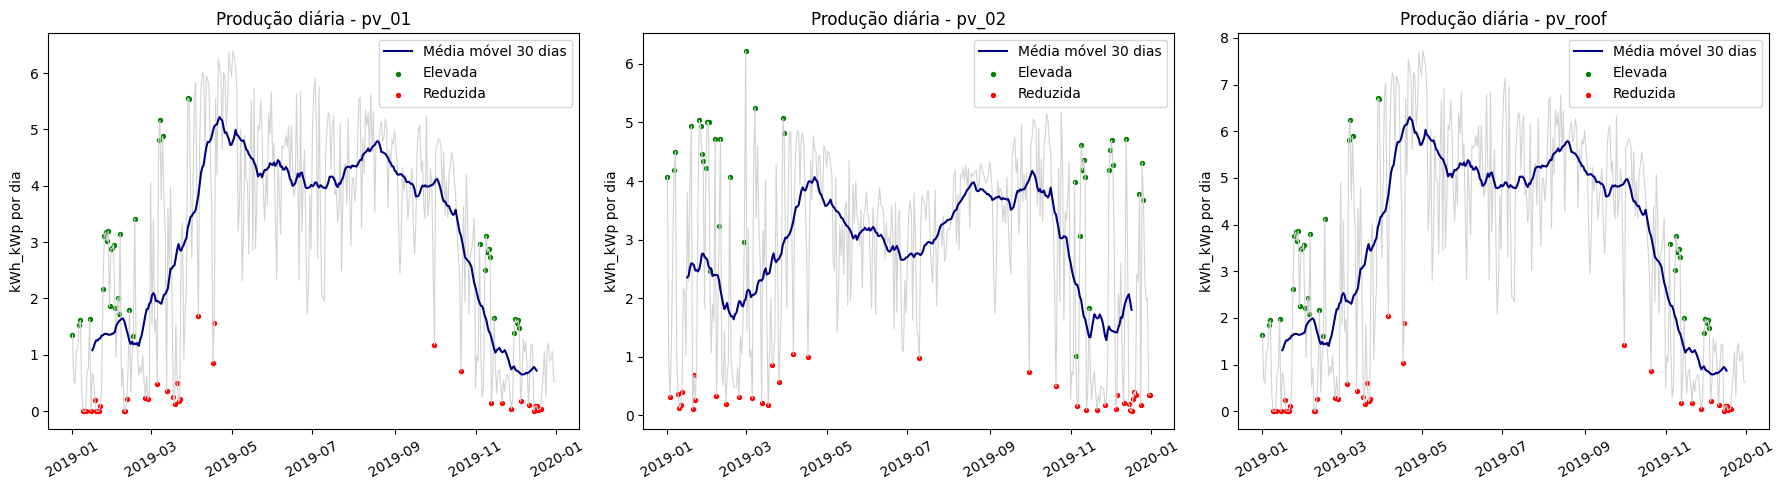

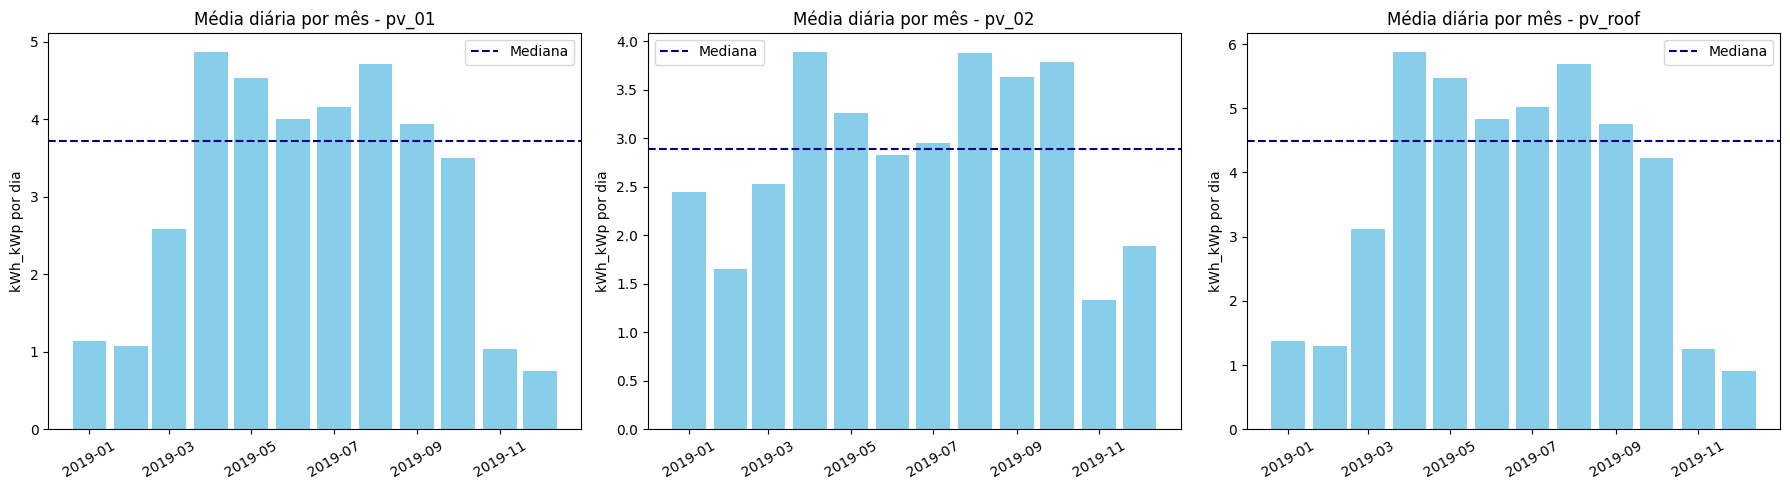


===== pv_01 =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-18 2019-01-22     5
2019-01-09 2019-01-11     3
2019-02-09 2019-02-11     3
2019-03-21 2019-03-23     3
Períodos ELEVADOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-01-24 2019-02-02    10
2019-11-08 2019-11-12     5
2019-11-30 2019-12-04     5
2019-02-04 2019-02-06     3

===== pv_02 =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-09 2019-01-12     4
2019-01-20 2019-01-22     3
Períodos ELEVADOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-11-08 2019-11-12     5
2019-01-25 2019-01-28     4
2019-01-30 2019-02-02     4
2019-11-30 2019-12-03     4

===== pv_roof =====
Períodos REDUZIDOS (>= 3 dias seguidos):
    inicio        fim  dias
2019-12-15 2019-12-20     6
2019-01-18 2019-01-22     5
2019-01-09 2019-01-11     3
2019-02-09 2019-02-11     3
2019-03-21 2019-03-23     3
Períodos E

In [15]:
colunas_producao = ["pv_01", "pv_02", "pv_roof"]

# Total diário (com zeros). min_count=1 -> dias sem dados ficam NaN em vez de 0
diario = pv_idx[colunas_producao].resample("D").sum(min_count=1)

# Produção relativa à mediana do mesmo mês (remove a sazonalidade)
ref_mes = diario.groupby(diario.index.month).transform("median")
rel = diario / ref_mes

# Limiares: 10% piores e 10% melhores dias (ajusta 0.10 / 0.90 se quiseres)
p_baixo, p_alto = rel.quantile(0.10), rel.quantile(0.90)

# --- 1. TOTAL DIÁRIO com dias elevados (verde) e reduzidos (vermelho) ---
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    alto = rel[col] >= p_alto[col]
    baixo = rel[col] <= p_baixo[col]
    plt.plot(diario.index, diario[col], color="lightgray", lw=0.8)
    plt.plot(diario.index, diario[col].rolling(30, center=True).mean(),
             color="navy", lw=1.5, label="Média móvel 30 dias")
    plt.scatter(diario.index[alto], diario[col][alto], s=8, color="green", label="Elevada")
    plt.scatter(diario.index[baixo], diario[col][baixo], s=8, color="red", label="Reduzida")
    plt.title(f"Produção diária - {col}")
    plt.ylabel("kWh_kWp por dia")
    plt.xticks(rotation=30)
    plt.legend()
plt.tight_layout()
plt.savefig("periodos_producao_diaria.png", dpi=150)
plt.show()

# --- 2. PRODUÇÃO MÉDIA DIÁRIA POR MÊS (cada mês de cada ano) ---
mensal = diario.resample("MS").mean()
plt.figure(figsize=(18, 5))
for i, col in enumerate(colunas_producao, 1):
    plt.subplot(1, 3, i)
    plt.bar(mensal.index, mensal[col], width=25, color="skyblue")
    plt.axhline(mensal[col].median(), color="navy", ls="--", label="Mediana")
    plt.title(f"Média diária por mês - {col}")
    plt.ylabel("kWh_kWp por dia")
    plt.xticks(rotation=30)
    plt.legend()
plt.tight_layout()
plt.savefig("periodos_producao_mensal.png", dpi=150)
plt.show()

# --- 3. SEQUÊNCIAS DE DIAS CONSECUTIVOS ELEVADOS / REDUZIDOS ---
def sequencias(mask, min_dias=3):
    grupos = (mask != mask.shift()).cumsum()
    out = []
    for _, g in mask.groupby(grupos):
        if g.iloc[0] and len(g) >= min_dias:
            out.append((g.index[0].date(), g.index[-1].date(), len(g)))
    return (pd.DataFrame(out, columns=["inicio", "fim", "dias"])
            .sort_values("dias", ascending=False).head(10))

for col in colunas_producao:
    print(f"\n===== {col} =====")
    print("Períodos REDUZIDOS (>= 3 dias seguidos):")
    print(sequencias(rel[col] <= p_baixo[col]).to_string(index=False))
    print("Períodos ELEVADOS (>= 3 dias seguidos):")
    print(sequencias(rel[col] >= p_alto[col]).to_string(index=False))

# --- 4. TOP 5 MELHORES E PIORES MESES ---
for col in colunas_producao:
    m = mensal[col].dropna().sort_values()
    print(f"\n{col} - 5 meses mais fracos:\n{m.head(5).round(3)}")
    print(f"{col} - 5 meses mais fortes:\n{m.tail(5).round(3)}")

# 4.2 Preparação dos dados 


## Resolver valores Inconsistentes

Após a análise destes valores chego à conclusão que não faz sentido modificar ou remover os 89 valores inconsistentes que existem visto que os valores estão muito perto de uma possível realidade que é existe dias de verão em que o sol mesmo às cinco da manhã pode estar a emitir radiação suficiente para dar os valores que deram.

## Outliers

Neste tipo de dataset é complicado de analisar os outliers visto que temos variáveis com muitos zeros e também podemos ter os casos de dias mais ou menos nublados. Então a solução encontrada é agrupar os dados por mês, data e hora, para que consigamos fazer a análise de dados por grupos que façam sentido, conseguindo então "ignorar" os zeros.

Vão ser aplicados então três métodos diferentes para conseguir definir melhor os outliers:

- 1º Método: comparar todas as horas iguais de todos os dias do ano
- 2º Método: comparar por parques de geração, ou seja comparar o rácio entre parques
- 3º Método: comparar os totais diários, ou seja se para o mês que é aquele total faz sentido ou não

### Preparação
Agrupar por mês, data e hora

In [16]:
SERIES = ["pv_01", "pv_02", "pv_roof"]
outliers = pv_geral.set_index("Datetime")[SERIES].copy()
outliers["hora"] = outliers.index.hour
outliers["mes"] = outliers.index.month
outliers["data"] = outliers.index.date

outliers = []

In [19]:
SERIES = ["pv_01", "pv_02", "pv_roof"]

# DataFrame com os dados: índice Datetime e colunas pv_01, pv_02, pv_roof
dados = pv_idx.copy()                     # o teu DataFrame com índice Datetime
dados["hora"] = dados.index.hour
dados["mes"] = dados.index.month
dados["data"] = dados.index.date

def mad_z(x):
    med = x.median()
    mad = (x - med).abs().median()
    return 0.6745 * (x - med) / mad if mad > 0 else pd.Series(0.0, index=x.index)

resultados = []      # lista onde se acumulam os pontos sinalizados

# ---------- 1) Por hora e mês (só horas com produção) ----------
for s in SERIES:
    dia = dados[dados[s] > 0.02]
    z = dia.groupby(["mes", "hora"])[s].transform(mad_z)
    mask = z.abs() > 3.5
    sub = dia.loc[mask, [s]].copy()
    sub["z"] = z[mask]
    sub["serie"] = s
    sub["metodo"] = "1) fora do típico da hora/mês"
    resultados.append(sub.rename(columns={s: "valor"}))

# ---------- 2) Entre séries ----------
for s in SERIES:
    outras = [c for c in SERIES if c != s]
    ref = dados[outras].mean(axis=1)
    m = (dados[s] > 0.05) & (ref > 0.05)
    ratio = dados.loc[m, s] / ref[m]
    z = ratio.groupby(dados.loc[m, "mes"]).transform(mad_z)
    mask = z.abs() > 3.5
    sub = dados.loc[z.index[mask], [s]].copy()
    sub["z"] = z[mask]
    sub["serie"] = s
    sub["metodo"] = "2) desvio face às outras séries"
    resultados.append(sub.rename(columns={s: "valor"}))

# ---------- 3) Totais diários ----------
diario = dados.groupby("data")[SERIES].sum()
diario.index = pd.to_datetime(diario.index)
for s in SERIES:
    z = diario[s].groupby(diario.index.month).transform(mad_z)
    mask = z.abs() > 3.5
    sub = diario.loc[mask, [s]].copy()
    sub["z"] = z[mask]
    sub["serie"] = s
    sub["metodo"] = "3) total diário atípico"
    resultados.append(sub.rename(columns={s: "valor"}))

out = pd.concat(resultados)
out.index.name = "Datetime"
out = out.sort_values(["serie", "metodo", "Datetime"])

print(out.groupby(["serie", "metodo"]).size().unstack(fill_value=0))

# Pontos sinalizados simultaneamente pelos métodos 1 e 2 (os mais fiáveis)
m1 = out[out["metodo"].str.startswith("1")].reset_index().set_index(["Datetime", "serie"]).index
m2 = out[out["metodo"].str.startswith("2")].reset_index().set_index(["Datetime", "serie"]).index
print(m1.intersection(m2))

out.to_csv("outliers.csv")

metodo   1) fora do típico da hora/mês  2) desvio face às outras séries  \
serie                                                                     
pv_01                              184                               17   
pv_02                              276                              196   
pv_roof                            181                               21   

metodo   3) total diário atípico  
serie                             
pv_01                         11  
pv_02                         22  
pv_roof                       11  
MultiIndex([('2019-02-06 09:00:00',   'pv_01'),
            ('2019-02-17 08:00:00',   'pv_01'),
            ('2019-02-01 08:00:00',   'pv_02'),
            ('2019-02-01 09:00:00',   'pv_02'),
            ('2019-02-06 08:00:00',   'pv_02'),
            ('2019-02-06 09:00:00',   'pv_02'),
            ('2019-02-17 08:00:00',   'pv_02'),
            ('2019-03-29 08:00:00',   'pv_02'),
            ('2019-03-30 08:00:00',   'pv_02'),
            ('201

In [21]:
# dias marcados pelo método 3
dias_m3 = out[out["metodo"].str.startswith("3")].reset_index()
dias_m3["dia"] = pd.to_datetime(dias_m3["Datetime"]).dt.normalize()
dias_m3 = set(zip(dias_m3["dia"], dias_m3["serie"]))

confirmados = m1.intersection(m2)

niveis = []
for dt, s in confirmados:
    dt = pd.Timestamp(dt)
    nivel = "alta" if (dt.normalize(), s) in dias_m3 else "confirmado"
    niveis.append(dict(Datetime=dt, serie=s, nivel=nivel, valor=dados.loc[dt, s]))

niveis = pd.DataFrame(niveis).sort_values(["serie", "Datetime"])
print(niveis.groupby(["serie", "nivel"]).size().unstack(fill_value=0))
niveis.to_csv("outliers_por_nivel.csv", index=False)

nivel    alta  confirmado
serie                    
pv_01       1           1
pv_02      13           7
pv_roof     1           0


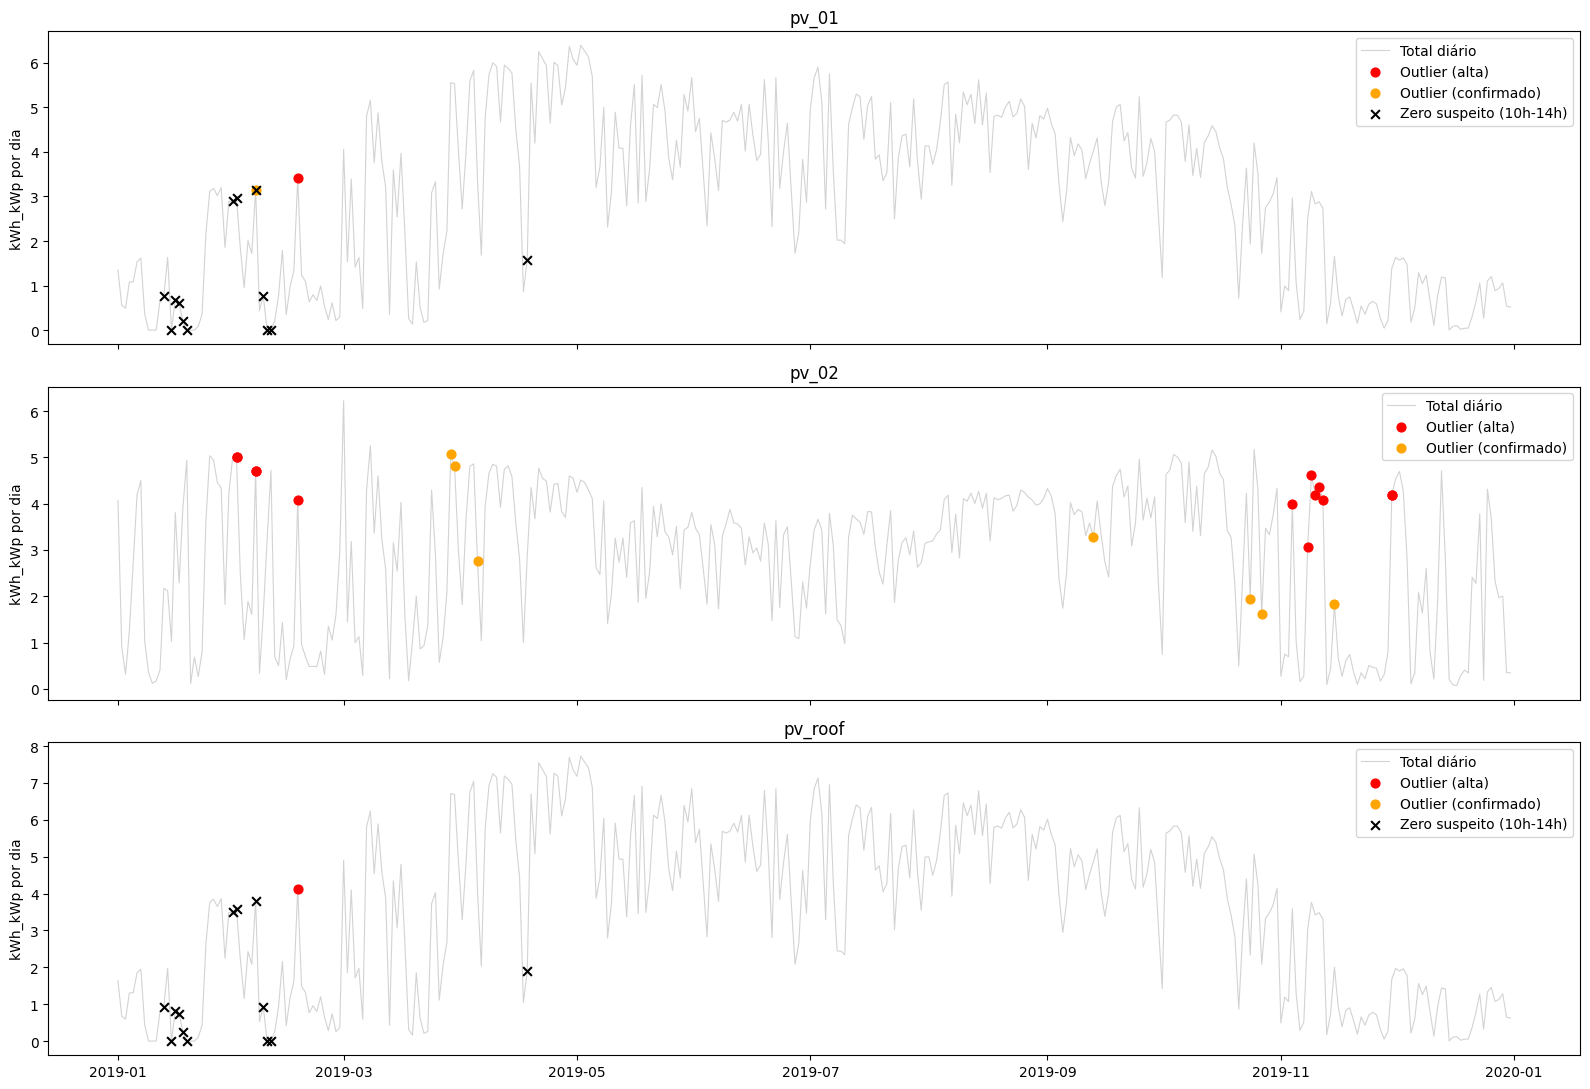

In [27]:
SERIES = ["pv_01", "pv_02", "pv_roof"]
cores = {"alta": "red", "confirmado": "orange"}

# Zeros suspeitos de dia (os 31 pontos), para mostrar também
meio = (dados.index.hour >= 10) & (dados.index.hour <= 14)
zeros_sus = {
    "pv_01": dados.index[meio & (dados["pv_01"] == 0) & (dados[["pv_02", "pv_roof"]].mean(axis=1) > 0.2)],
    "pv_roof": dados.index[meio & (dados["pv_roof"] == 0) & (dados[["pv_01", "pv_02"]].mean(axis=1) > 0.2)],
    "pv_02": pd.DatetimeIndex([]),
}

diario = dados[SERIES].resample("D").sum(min_count=1)

fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
for ax, s in zip(axes, SERIES):
    ax.plot(diario.index, diario[s], color="lightgray", lw=0.8, label="Total diário")

    # outliers do método (nível alta / confirmado), marcados no dia correspondente
    for nivel, cor in cores.items():
        pts = niveis[(niveis["serie"] == s) & (niveis["nivel"] == nivel)]
        dias = pd.to_datetime(pts["Datetime"]).dt.normalize()
        ax.scatter(dias, diario[s].reindex(dias), color=cor, s=40, zorder=3, label=f"Outlier ({nivel})")

    # zeros suspeitos
    dz = zeros_sus[s].normalize().unique()
    if len(dz):
        ax.scatter(dz, diario[s].reindex(dz), marker="x", color="black", s=40, zorder=3, label="Zero suspeito (10h-14h)")

    ax.set_title(s)
    ax.set_ylabel("kWh_kWp por dia")
    ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("outliers_localizacao.png", dpi=150)
plt.show()

In [28]:
dados_limpo = dados[SERIES].copy()
erros = pd.DataFrame(False, index=dados.index, columns=SERIES)

# A) zeros suspeitos
erros.loc[zeros_sus["pv_01"], "pv_01"] = True
erros.loc[zeros_sus["pv_roof"], "pv_roof"] = True

# B) pontos 'niveis' que não são explicados pelo padrão normal da hora
ref_ = {s: dados[[c for c in SERIES if c != s]].mean(axis=1) for s in SERIES}
for s in SERIES:
    r = (dados[s] / ref_[s]).where(ref_[s] > 0.05)
    r_hora = r.groupby(dados.index.hour).transform("median")
    desvio = r / r_hora                                  # ~1 = normal para essa hora
    pts = pd.to_datetime(niveis.loc[niveis["serie"] == s, "Datetime"])
    ruins = desvio.reindex(pts)
    mau = ruins[(ruins < 0.4) | (ruins > 2.5)].index     # só os claramente fora
    erros.loc[mau, s] = True

print("Pontos a corrigir:", erros.sum().to_dict())

# C) corrigir: estimativa pelo pv_02 (zeros) / interpolação (restantes)
for s in SERIES:
    dados_limpo[f"{s}_corrigido"] = erros[s].astype(int)

for s in ["pv_01", "pv_roof"]:
    ok = (~erros[s]) & (dados["pv_02"] > 0.05) & (dados[s] > 0.05)
    rac = dados.loc[ok, s] / dados.loc[ok, "pv_02"]
    rac_tipico = rac.groupby([rac.index.month, rac.index.hour]).median()
    chave = pd.MultiIndex.from_arrays([dados.index.month, dados.index.hour])
    estimado = pd.Series(dados["pv_02"].values * rac_tipico.reindex(chave).values, index=dados.index)
    dados_limpo.loc[erros[s], s] = estimado[erros[s]]

# pv_02 (se tiver erros): NaN e interpolação curta
dados_limpo.loc[erros["pv_02"], "pv_02"] = np.nan
dados_limpo["pv_02"] = dados_limpo["pv_02"].interpolate(method="time", limit=3, limit_area="inside")

print("NaN restantes:", dados_limpo[SERIES].isna().sum().to_dict())

Pontos a corrigir: {'pv_01': 31, 'pv_02': 12, 'pv_roof': 31}
NaN restantes: {'pv_01': 0, 'pv_02': 0, 'pv_roof': 0}


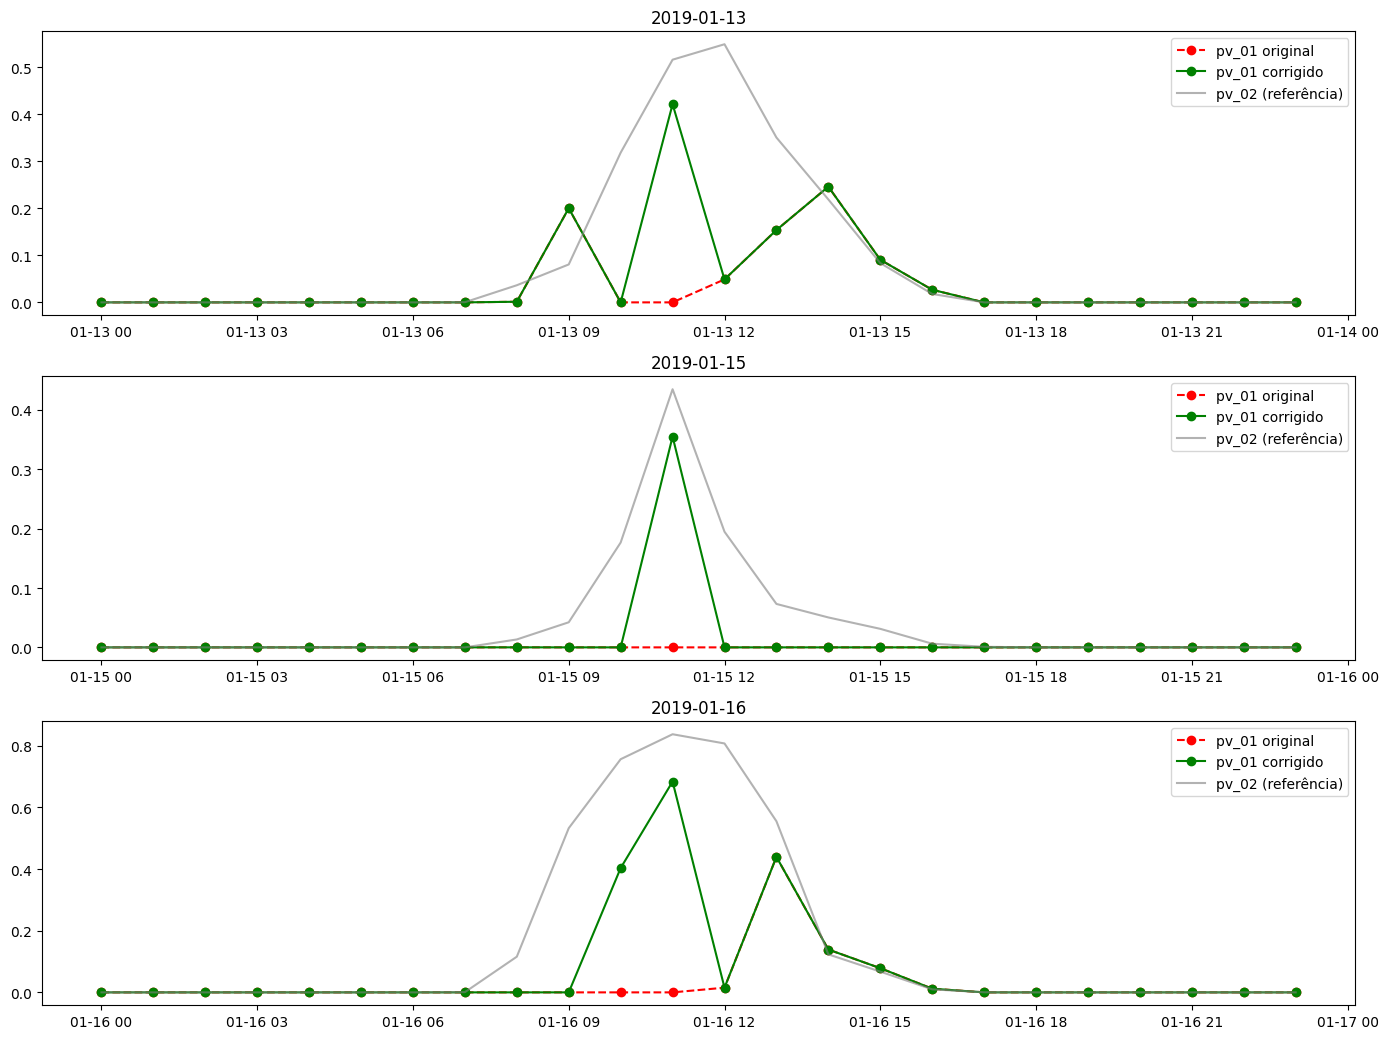

          pv_01     pv_02   pv_roof
count  8760.000  8760.000  8760.000
mean      0.126     0.119     0.153
std       0.210     0.196     0.253
min       0.000     0.000     0.000
25%       0.000     0.000     0.000
50%       0.000     0.003     0.000
75%       0.168     0.148     0.202
max       0.785     0.865     0.948
          pv_01     pv_02   pv_roof
count  8760.000  8760.000  8760.000
mean      0.129     0.118     0.156
std       0.213     0.196     0.257
min       0.000     0.000     0.000
25%       0.000     0.000     0.000
50%       0.000     0.003     0.000
75%       0.175     0.147     0.211
max       1.102     0.865     1.293


In [29]:
datas = sorted(set(zeros_sus["pv_01"].normalize()))[:3]      # 3 dias afetados
fig, axes = plt.subplots(len(datas), 1, figsize=(14, 3.5 * len(datas)), squeeze=False)
for ax, d in zip(axes[:, 0], datas):
    sl = slice(d, d + pd.Timedelta(hours=23))
    ax.plot(dados.loc[sl, "pv_01"], "o--", color="red", label="pv_01 original")
    ax.plot(dados_limpo.loc[sl, "pv_01"], "o-", color="green", label="pv_01 corrigido")
    ax.plot(dados.loc[sl, "pv_02"], color="gray", alpha=0.6, label="pv_02 (referência)")
    ax.set_title(str(d.date())); ax.legend()
plt.tight_layout(); plt.show()

print(dados[SERIES].describe().round(3))
print(dados_limpo[SERIES].describe().round(3))

Deteção. Os valores atípicos foram identificados por três métodos complementares, todos baseados no z-score modificado com a mediana e o desvio absoluto mediano (MAD), que é robusto à presença dos próprios extremos. Foi usado o limiar de 3,5, e as horas sem produção (noite e crepúsculo) foram excluídas da análise, porque os zeros noturnos são valores reais.

Desvio face ao típico da hora e do mês: cada valor foi comparado com os restantes registos da mesma hora e do mesmo mês, para não classificar como anómalo o que é normal numa dada época do ano.
Desvio face às outras séries: como os sistemas fotovoltaicos se encontram no mesmo local e recebem a mesma radiação, o rácio entre cada série e a média das restantes deve ser estável. Este método é o mais fiável para distinguir falhas de medição de variações meteorológicas.
Total diário atípico: os totais diários foram comparados com os restantes dias do mesmo mês.

Os pontos sinalizados simultaneamente pelos métodos 1 e 2 foram considerados candidatos confirmados. Destes, os que pertenciam também a um dia atípico no método 3 foram classificados com nível “alta”, e os restantes com nível “confirmado”.

Análise individual. Dado o número reduzido de candidatos, cada um foi analisado individualmente, em vez de aplicar uma regra automática de remoção. Em séries de produção fotovoltaica, valores extremos podem ser reais (dias de céu limpo, reflexos de nuvens), pelo que a remoção indiscriminada eliminaria informação útil para o modelo.

Dessa análise resultaram duas conclusões:

Falsos positivos associados à orientação do sistema. Os pontos sinalizados na série pv_02 ocorrem de manhã (8h-9h), e nesses instantes a série apresenta sistematicamente um valor entre 3 e 4 vezes superior ao das restantes, de forma estável. Este comportamento é compatível com uma orientação diferente do sistema, que produz mais no início do dia, e não com uma falha de medição. Estes pontos foram mantidos. A limitação do método 2 foi identificada: calcula o rácio por mês, mas não por hora do dia.
Falhas de registo. Foram detetados [31] registos em que pv_01 e pv_roof apresentavam produção nula entre as 10h e as 14h, em simultâneo, enquanto pv_02 registava produção normal (0,4 a 0,8 kWh/kWp). A coincidência total entre as duas séries, a ausência do fenómeno no verão e a incoerência física de produção nula ao meio-dia com radiação elevada levaram a classificá-los como falhas de registo, e não como comportamento real do sistema.

Tratamento. Os registos classificados como erro foram marcados como valores em falta, sem remover as linhas, para preservar a regularidade temporal da série e a integridade das variáveis de desfasamento (lags). O preenchimento foi feito de duas formas:

Para pv_01 e pv_roof, os valores foram estimados a partir de pv_02 multiplicado pela razão mediana típica entre os sistemas para a mesma hora e mês, calculada apenas com registos válidos. Este método respeita o nível de radiação do próprio dia, algo que a interpolação linear não consegue em lacunas de várias horas.
Para eventuais erros isolados em pv_02, foi usada interpolação temporal, limitada a lacunas de 3 horas.